In [1]:
# Keep imports and data/output paths relative to the repository root.
import os
import sys
from pathlib import Path
from datetime import datetime
from uuid import uuid4

for repository_dir in (Path.cwd(), *Path.cwd().parents):
    if (repository_dir / ".geofm-root").is_file():
        os.chdir(repository_dir)
        break
else:
    raise FileNotFoundError("Open this notebook from inside the repository.")
if "src" not in sys.path:
    sys.path.insert(0, "src")

EXPERIMENT_NAME = "sen1floods11/croma/fcn_s2"
NOTEBOOK_PATH = "experiments/sen1floods11/croma/fcn_s2/01_croma_on_sen1floods11_training_s2.ipynb"


#### **Imports**

In [2]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as FT
import torch.nn.functional as F
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
import json

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.segmentation.fcn import FCNHead
from use_croma import PretrainedCROMA
import pandas as pd
from IPython.display import display
from segmentation_metrics import binary_metrics, METRIC_KEYS, metric_table, clean_json


In [3]:
# Optical-only helpers live here to keep this experiment self-contained.
# Reference: https://github.com/antofuller/CROMA#using-pretrained-croma-models
CROP_SIZE = 120
IGNORE_INDEX = 255
SCHEMA = "croma_s2_fcn_v1"
S2_BANDS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13]  # Rasterio indices; omit B10/cirrus.
PREPROCESSING = {
    "modality": "optical", "bands": S2_BANDS,
    "band_names": ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"],
    "normalization": "per_full_image_band_mean_plus_minus_2std_float_0_1",
    "statistics": "finite_non_nodata_pixels", "invalid_input_fill_after_normalization": 0,
    "ignore_index": IGNORE_INDEX,
}
SEED = 234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

def load_split_paths(csv_file, x_dir, y_dir):
    pairs = []
    with open(csv_file, newline="") as handle:
        for x_name, y_name in csv.reader(handle):
            chip = x_name.strip().removesuffix("_S1Hand.tif")
            if y_name.strip() != chip + "_LabelHand.tif":
                raise ValueError(f"Mismatched split row: {x_name}, {y_name}")
            x_path, y_path = Path(x_dir) / (chip + "_S2Hand.tif"), Path(y_dir) / y_name.strip()
            if not x_path.is_file() or not y_path.is_file():
                raise FileNotFoundError(f"Missing pair: {x_path}, {y_path}")
            with rasterio.open(x_path) as x, rasterio.open(y_path) as y:
                if (x.count != 13 or x.shape != y.shape or x.crs != y.crs
                        or not x.transform.almost_equals(y.transform, precision=1e-10)):
                    raise ValueError(f"Band/grid mismatch: {chip}")
            pairs.append((x_path, y_path))
    return pairs

def load_image_pair(pair):
    with rasterio.open(pair[0]) as src:
        image = src.read(S2_BANDS, out_dtype="float32", masked=True).filled(np.nan)
    with rasterio.open(pair[1]) as src:
        mask = src.read(1).astype(np.int64)
    return image, mask

def prepare_sample(data):
    raw, mask = data
    image = torch.as_tensor(raw, dtype=torch.float32)
    mask = torch.as_tensor(mask, dtype=torch.long).clone()
    mask[mask == -1] = IGNORE_INDEX
    if image.shape[0] != 12 or image.shape[-2:] != mask.shape:
        raise ValueError("Expected aligned 12-band optical image and label.")
    if not set(torch.unique(mask).tolist()).issubset({0, 1, IGNORE_INDEX}):
        raise ValueError("Unexpected label values.")
    normalized = torch.zeros_like(image)
    # CROMA's float normalization, applied per full image before cropping/tiling.
    # Exclude nodata from statistics; handle empty/constant channels explicitly.
    for band in range(12):
        valid = torch.isfinite(image[band])
        values = image[band][valid]
        if values.numel() < 2:
            continue
        mean, std = values.mean(), values.std()
        if std > 1e-6:
            normalized[band][valid] = ((values - (mean - 2 * std)) / (4 * std)).clamp(0, 1)
        else:
            normalized[band][valid] = 0.5
    return normalized, mask

class Sen1Floods11Dataset(Dataset):
    def __init__(self, data_list, preprocess_func):
        self.data_list, self.preprocess_func = data_list, preprocess_func
    def __len__(self):
        return len(self.data_list)
    def __getitem__(self, index):
        return self.preprocess_func(load_image_pair(self.data_list[index]))

class CROMAFloodSegmentation(nn.Module):
    def __init__(self, croma, head):
        super().__init__()
        self.croma, self.head = croma, head
    def train(self, mode=True):
        super().train(mode)
        self.croma.eval()
        return self
    def forward(self, images):
        with torch.no_grad():
            features = self.croma(optical_images=images)["optical_encodings"]
        batch, tokens, channels = features.shape
        side = int(tokens ** 0.5)
        assert side * side == tokens
        features = features.transpose(1, 2).reshape(batch, channels, side, side)
        return F.interpolate(self.head(features), size=images.shape[-2:],
                             mode="bilinear", align_corners=False)


#### **First things first**


In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pretrained_path = "pretrained/croma/CROMA_large.pt"

path_to_the_dataset = "datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/"

path_to_the_dataset_index = "datasets/sen1floods11/sen1floods11_hand_labeled_only/flood_handlabeled/"

path_to_X = path_to_the_dataset + "S2Hand/"

path_to_Y = path_to_the_dataset + "LabelHand/"

path_to_train_csv = path_to_the_dataset_index + "flood_train_data.csv"

path_to_val_csv = path_to_the_dataset_index + "flood_valid_data.csv"

path_to_test_csv = path_to_the_dataset_index + "flood_test_data.csv"
path_to_test_bolivia_csv = path_to_the_dataset_index + "flood_bolivia_data.csv"

print(device)

cuda


In [5]:
CROP_SIZE = 120
IGNORE_INDEX = 255

#### **Functions**

In [6]:
def preprocess_train(data):
    """
    Normalize the complete image,
    extract a random 120x120 crop,
    and apply synchronized random flips.
    """

    image, mask = prepare_sample(data)

    H, W = image.shape[-2:]

    assert H >= CROP_SIZE and W >= CROP_SIZE

    # Random crop coordinates
    top = torch.randint(
        0, H - CROP_SIZE + 1, (1,)
    ).item()

    left = torch.randint(
        0, W - CROP_SIZE + 1, (1,)
    ).item()

    # Same crop for image and ground-truth mask
    image = image[
        :, top:top + CROP_SIZE, left:left + CROP_SIZE
    ]

    mask = mask[
        top:top + CROP_SIZE, left:left + CROP_SIZE
    ]

    # Random horizontal flip
    if torch.rand(()) < 0.5:
        image = image.flip(-1)
        mask = mask.flip(-1)

    # Random vertical flip
    if torch.rand(()) < 0.5:
        image = image.flip(-2)
        mask = mask.flip(-2)

    return image, mask



def preprocess_eval(data):
   
    return prepare_sample(data)

#### Creating datasets

In [7]:

# Preserve official split membership and order, including fully ignored/empty scenes.
split_files = {"train": "flood_train_data.csv", "valid": "flood_valid_data.csv",
               "non_bol": "flood_test_data.csv", "bol": "flood_bolivia_data.csv"}
expected_counts = {"train": 252, "valid": 89, "non_bol": 90, "bol": 15}
all_splits = {name: load_split_paths(Path(path_to_the_dataset_index) / filename, path_to_X, path_to_Y)
              for name, filename in split_files.items()}
for name, pairs in all_splits.items():
    assert len(pairs) == expected_counts[name], (name, len(pairs))
    assert len({x.stem for x, _ in pairs}) == len(pairs), f"Duplicates in {name}"
for i, name in enumerate(all_splits):
    for other in list(all_splits)[i+1:]:
        assert not ({x.stem for x, _ in all_splits[name]} & {x.stem for x, _ in all_splits[other]})
print("Verified S2/label grids and disjoint split counts:", {k: len(v) for k, v in all_splits.items()})

train_data = all_splits["train"]
val_data = all_splits["valid"]


Verified S2/label grids and disjoint split counts: {'train': 252, 'valid': 89, 'non_bol': 90, 'bol': 15}


In [8]:
print(f"Train samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")

Train samples: 252
Validation samples: 89


In [9]:
print(train_data[0])

(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S2Hand/Ghana_103272_S2Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Ghana_103272_LabelHand.tif'))


In [10]:
train_dataset = Sen1Floods11Dataset(
    data_list=train_data,
    preprocess_func=preprocess_train
)

valid_dataset = Sen1Floods11Dataset(
    data_list=val_data,
    preprocess_func=preprocess_eval
)

#### Creating DataLoaders

In [11]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Training batch checks

images, masks = next(iter(train_loader))

print("Training images:", images.shape)
print("Training masks:", masks.shape)

print("Image min:", images.min().item())
print("Image max:", images.max().item())

print("Water pixels:", (masks == 1).sum().item())
print("Non-water pixels:", (masks == 0).sum().item())
print("Ignored pixels:", (masks == IGNORE_INDEX).sum().item())

assert torch.isfinite(images).all()

assert set(torch.unique(masks).tolist()).issubset(
    {0, 1, IGNORE_INDEX}
)

# Validation batch checks

val_images, val_masks = next(iter(valid_loader))

print("-" * 40)
print("Validation images:", val_images.shape)
print("Validation masks:", val_masks.shape)

Training images: torch.Size([16, 12, 120, 120])
Training masks: torch.Size([16, 120, 120])
Image min: 0.0
Image max: 1.0
Water pixels: 35602
Non-water pixels: 162611
Ignored pixels: 32187
----------------------------------------
Validation images: torch.Size([1, 12, 512, 512])
Validation masks: torch.Size([1, 512, 512])


##### Loading CROMA

In [12]:
croma = PretrainedCROMA(pretrained_path= pretrained_path, 
                        size='large', 
                        modality='optical', 
                        image_resolution=120)

croma = croma.to(device)

Initializing optical encoder


In [13]:
croma.requires_grad_(False) # Freeze the weights of CROMA
croma.eval()

PretrainedCROMA(
  (s2_encoder): ViT(
    (linear_input): Linear(in_features=768, out_features=1024, bias=True)
    (transformer): BaseTransformer(
      (layers): ModuleList(
        (0-23): 24 x ModuleList(
          (0): Attention(
            (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
            (to_out): Linear(in_features=1024, out_features=1024, bias=True)
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
          (1): FFN(
            (net): Sequential(
              (0): Linear(in_features=1024, out_features=4096, bias=True)
              (1): GELU(approximate='none')
              (2): Dropout(p=0.0, inplace=False)
              (3): Linear(in_features=4096, out_features=1024, bias=True)
            )
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          )
        )
      )
      (norm_out): LayerNo

### Creating the head

In [14]:
head = FCNHead(in_channels=1024, channels=2)

head[1] = nn.GroupNorm(
    num_groups=16,
    num_channels=256
)

head = head.to(device)

In [15]:
model = CROMAFloodSegmentation(croma, head).to(device)

In [16]:
EVAL_INTERVAL = 2
LR = 5e-4

class_weights = torch.tensor(
    [1.0, 8.0],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=IGNORE_INDEX
)

optimizer = torch.optim.AdamW(
    model.head.parameters(),
    lr=LR,
    weight_decay=1e-2
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=len(train_loader) * 10,
    T_mult=2,
    eta_min=0
)

In [17]:
def train_one_epoch(model, train_loader, optimizer, criterion, device):

    model.train()

    total_loss = 0.0
    total_weight = 0

    for images, masks in train_loader:

        # Move batch to GPU
        images = images.to(device)
        masks = masks.to(device)

        valid = masks != IGNORE_INDEX

        if not valid.any():
            continue

        # Reset previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        logits = model(images)

        # Compute segmentation loss
        loss = criterion(logits, masks)

        # Backpropagation
        loss.backward()

        # Update FCN head weights
        optimizer.step()
        
        # Scheduler step
        scheduler.step()
        
        # Correct denominator of the weighted mean
        batch_weight = criterion.weight[masks[valid]].sum().item()

        total_loss += loss.item() * batch_weight
        total_weight += batch_weight

    if total_weight == 0:
        raise RuntimeError("No valid training pixels.")

    return total_loss / total_weight

In [18]:
@torch.inference_mode()
def sliding_window_logits(
    model,
    image,
    device,
    tile_size=120,
    stride=60,
    tile_batch_size=8
):
    """
    Predict segmentation logits for one complete image.

    Parameters
    ----------
    model:
        Frozen CROMA + trained FCN head.

    image:
        Tensor [12, H, W], already normalized.

    device:
        CUDA or CPU.

    tile_size:
        Spatial size of each CROMA input (120).

    stride:
        Distance between consecutive windows (60 = 50% overlap).

    tile_batch_size:
        Number of windows processed simultaneously.

    Returns
    -------
    logits:
        Tensor [2, H, W] on CPU.
    """

    model.eval()

    C, H, W = image.shape

    assert C == 12
    assert H >= tile_size and W >= tile_size
    assert 0 < stride <= tile_size

    # Generate starting positions along one dimension
    def get_starts(length):
        starts = list(
            range(0, length - tile_size + 1, stride)
        )

        # Ensure the final window reaches the image boundary
        if starts[-1] != length - tile_size:
            starts.append(length - tile_size)

        return starts

    # All window coordinates
    positions = [
        (top, left)
        for top in get_starts(H)
        for left in get_starts(W)
    ]

    # Accumulate predictions and coverage counts
    logits_sum = torch.zeros((2, H, W), dtype=torch.float32)
    counts = torch.zeros((H, W), dtype=torch.float32)

    # Process windows in batches
    for start in range(0, len(positions), tile_batch_size):

        batch_positions = positions[start:start + tile_batch_size]

        # Extract tiles
        tiles = torch.stack([
            image[:, top:top + tile_size, left:left + tile_size]
            for top, left in batch_positions
        ])

        tiles = tiles.to(device)

        # Run frozen CROMA + FCN head
        outputs = model(tiles).cpu()

        # Place tile predictions back into the full image
        for (top, left), logits in zip(batch_positions, outputs):

            logits_sum[
                :, top:top + tile_size, left:left + tile_size
            ] += logits

            counts[
                top:top + tile_size, left:left + tile_size
            ] += 1

    assert (counts > 0).all(), "Some pixels were not covered."

    # Average logits wherever windows overlap
    return logits_sum / counts.unsqueeze(0)


import torch.nn.functional as F

@torch.inference_mode()
def validate(model, valid_loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_valid_pixels = 0

    TP = FP = FN = TN = 0

    for images, masks in valid_loader:

        # Process every complete image in the batch.
        for image, mask in zip(images, masks):
            mask = mask.cpu()
            
            
            valid = mask != IGNORE_INDEX

            if not valid.any():
                continue

            # Reconstruct logits using overlapping windows.
            logits = sliding_window_logits(
                model,
                image,
                device,
                tile_size=CROP_SIZE,
                stride=CROP_SIZE // 2,
                tile_batch_size=8
            )
            
            logits_device = logits.unsqueeze(0).to(device)
            mask_device = mask.unsqueeze(0).to(device=device, dtype=torch.long)

            loss = criterion(logits_device, mask_device)

            image_weight = criterion.weight[
                mask_device[mask_device != IGNORE_INDEX]
            ].sum().item()

            total_loss += loss.item() * image_weight
            total_valid_pixels += image_weight

            prediction = logits.argmax(dim=0)

            TP += ((prediction == 1) & (mask == 1) & valid).sum().item()
            FP += ((prediction == 1) & (mask == 0) & valid).sum().item()
            FN += ((prediction == 0) & (mask == 1) & valid).sum().item()
            TN += ((prediction == 0) & (mask == 0) & valid).sum().item()

    if total_valid_pixels == 0:
        raise RuntimeError("No valid validation pixels.")

    val_loss = total_loss / total_valid_pixels

    return {"val_loss": val_loss, **binary_metrics(TP, FP, FN, TN)}


In [19]:
metrics = validate(model, valid_loader, criterion, device)
display(metric_table({"validation_baseline": metrics}).T)


split,validation_baseline
val_loss,6.765656e-01
accuracy,7.067434e-01
water_iou,1.360793e-01
nonwater_iou,6.925413e-01
miou,4.143103e-01
precision,1.677358e-01
recall,4.189533e-01
f1,2.395595e-01
omission_error,5.810467e-01
commission_error,8.322642e-01


In [20]:
EPOCHS = 100
best_val_iou = -1.0
best_epoch = None

model_name = "croma_large_s2_fcn_weighted_ce.pt"

# A new directory is created each time this run cell is executed.
run_id = datetime.now().astimezone().strftime("%Y-%m-%d_%H-%M-%S_%f") + "_" + uuid4().hex[:8]
checkpoint_dir = Path("runs") / EXPERIMENT_NAME / f"train_{Path(model_name).stem}_{run_id}"
checkpoint_dir.mkdir(parents=True, exist_ok=False)
print(f"Run directory: {checkpoint_dir}")
checkpoint_path = checkpoint_dir / model_name
history_path = checkpoint_dir / "croma_training_history.json"

with (checkpoint_dir / "run.json").open("w", encoding="utf-8") as run_file:
    json.dump({
        "experiment": EXPERIMENT_NAME,
        "model_name": checkpoint_path.stem,
        "phase": "train",
        "run_id": run_id,
        "started_at": datetime.now().astimezone().isoformat(),
        "notebook": NOTEBOOK_PATH,
        "pretrained_weights": pretrained_path,
        "schema": SCHEMA, "preprocessing": PREPROCESSING, "epochs": EPOCHS, "eval_interval": EVAL_INTERVAL,
        "seed": SEED, "split_counts": expected_counts, "modality": "optical",
    "checkpoint": checkpoint_path.as_posix(),
    "history": history_path.as_posix(),
    }, run_file, indent=4)


history = {"train_loss": [], "learning_rate": [], "val_loss": []}
history.update({"val_" + key: [] for key in METRIC_KEYS})
validation_rows = [{"epoch": 0, **metrics}]
pd.DataFrame(validation_rows).to_csv(checkpoint_dir / "validation_metrics.csv", index=False)

for epoch in range(EPOCHS):
    epoch_lr = optimizer.param_groups[0]["lr"]
    train_loss = train_one_epoch(
        model=model, criterion=criterion, train_loader=train_loader,
        device=device, optimizer=optimizer
    )
    evaluate_now = (epoch + 1) % EVAL_INTERVAL == 0 or epoch + 1 == EPOCHS
    metrics = validate(model, valid_loader, criterion, device) if evaluate_now else None

    history["train_loss"].append(train_loss)
    history["learning_rate"].append(epoch_lr)
    for key in ("val_loss", *METRIC_KEYS):
        history_key = key if key == "val_loss" else "val_" + key
        history[history_key].append(metrics[key] if metrics is not None else None)

    if metrics is not None:
        validation_rows.append({"epoch": epoch + 1, **metrics})
        pd.DataFrame(validation_rows).to_csv(checkpoint_dir / "validation_metrics.csv", index=False)
        display(metric_table({f"validation_epoch_{epoch+1}": metrics}).T)
        if metrics["water_iou"] > best_val_iou:
            best_val_iou = metrics["water_iou"]
            best_epoch = epoch + 1
            torch.save({
                "epoch": best_epoch,
                "schema": SCHEMA, "preprocessing": PREPROCESSING,
                "head_state_dict": model.head.state_dict(),
                "best_val_water_iou": best_val_iou,
                "val_miou": metrics["miou"], "val_loss": metrics["val_loss"],
                "validation_metrics": clean_json(metrics),
            }, checkpoint_path)

    with history_path.open("w", encoding="utf-8") as f:
        json.dump(clean_json({
            "epochs_completed": epoch + 1, "best_epoch": best_epoch,
            "best_val_water_iou": best_val_iou, "history": history,
        }), f, indent=4, allow_nan=False)
    pd.DataFrame(history, index=range(1, epoch + 2)).rename_axis("epoch").to_csv(
        checkpoint_dir / "all_metrics_history.csv"
    )
    message = f"Epoch [{epoch+1:02d}/{EPOCHS}] | LR: {epoch_lr:.2e} | Train Loss: {train_loss:.4f}"
    if metrics is not None:
        message += (f" | Val Loss: {metrics['val_loss']:.4f}"
                    f" | Water IoU: {metrics['water_iou']:.4f} | mIoU: {metrics['miou']:.4f}")
    print(message)

print(f"Best model: Epoch {best_epoch}, Water IoU = {best_val_iou:.4f}")


Run directory: runs\croma_sen1floods11\original_S2\train_croma_large_s2_fcn_weighted_ce_2026-10-23_08-59-24_626620_d48b9c97
Epoch [01/100] | LR: 5.00e-04 | Train Loss: 0.5415


split,validation_epoch_2
val_loss,3.535350e-01
accuracy,8.911151e-01
water_iou,4.429358e-01
nonwater_iou,8.807946e-01
miou,6.618652e-01
precision,5.039892e-01
recall,7.852414e-01
f1,6.139370e-01
omission_error,2.147586e-01
commission_error,4.960108e-01


Epoch [02/100] | LR: 4.88e-04 | Train Loss: 0.4063 | Val Loss: 0.3535 | Water IoU: 0.4429 | mIoU: 0.6619
Epoch [03/100] | LR: 4.52e-04 | Train Loss: 0.2958


split,validation_epoch_4
val_loss,2.588149e-01
accuracy,8.905879e-01
water_iou,4.736576e-01
nonwater_iou,8.786386e-01
miou,6.761481e-01
precision,5.021507e-01
recall,8.930200e-01
f1,6.428326e-01
omission_error,1.069800e-01
commission_error,4.978493e-01


Epoch [04/100] | LR: 3.97e-04 | Train Loss: 0.2906 | Val Loss: 0.2588 | Water IoU: 0.4737 | mIoU: 0.6761
Epoch [05/100] | LR: 3.27e-04 | Train Loss: 0.2394


split,validation_epoch_6
val_loss,2.332811e-01
accuracy,9.056223e-01
water_iou,5.112002e-01
nonwater_iou,8.952868e-01
miou,7.032435e-01
precision,5.437339e-01
recall,8.952183e-01
f1,6.765486e-01
omission_error,1.047817e-01
commission_error,4.562661e-01


... (91 outputs left out)

split,validation_epoch_98
val_loss,1.543202e-01
accuracy,9.414830e-01
water_iou,6.383278e-01
nonwater_iou,9.347433e-01
miou,7.865355e-01
precision,6.670935e-01
recall,9.367216e-01
f1,7.792430e-01
omission_error,6.327837e-02
commission_error,3.329065e-01


Epoch [98/100] | LR: 3.72e-04 | Train Loss: 0.1233 | Val Loss: 0.1543 | Water IoU: 0.6383 | mIoU: 0.7865
Epoch [99/100] | LR: 3.63e-04 | Train Loss: 0.1098


split,validation_epoch_100
val_loss,1.651935e-01
accuracy,9.486064e-01
water_iou,6.621943e-01
nonwater_iou,9.428486e-01
miou,8.025215e-01
precision,7.063448e-01
recall,9.137497e-01
f1,7.967712e-01
omission_error,8.625025e-02
commission_error,2.936552e-01


Epoch [100/100] | LR: 3.55e-04 | Train Loss: 0.1279 | Val Loss: 0.1652 | Water IoU: 0.6622 | mIoU: 0.8025
Best model: Epoch 38, Water IoU = 0.6781


In [21]:
print(
    "CROMA trainable parameters:",
    sum(p.numel() for p in model.croma.parameters()
        if p.requires_grad)
)

print(
    "Head trainable parameters:",
    sum(p.numel() for p in model.head.parameters()
        if p.requires_grad)
)

CROMA trainable parameters: 0
Head trainable parameters: 2360322


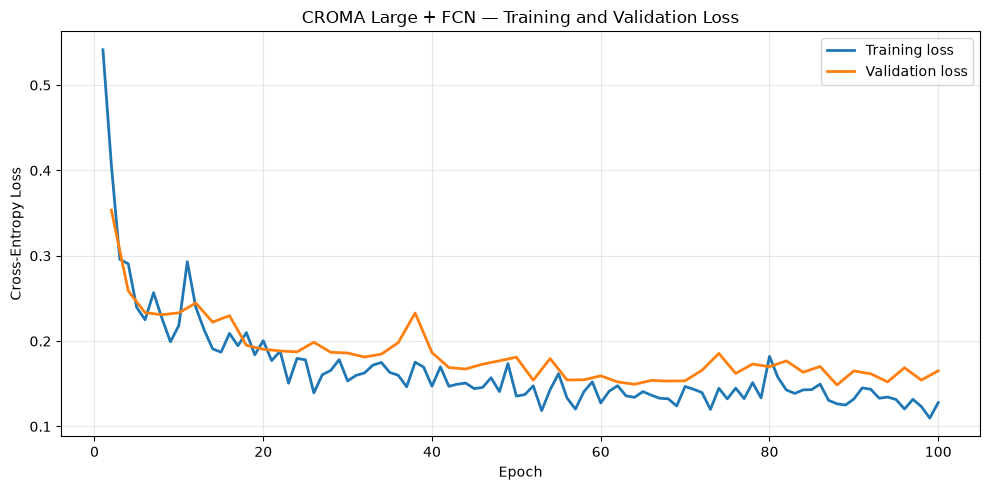

In [22]:
epochs = range(1, len(history["train_loss"]) + 1)
validation_epochs = [i + 1 for i, value in enumerate(history["val_loss"]) if value is not None]

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Training loss",
    linewidth=2
)

plt.plot(
    validation_epochs,
    [v for v in history["val_loss"] if v is not None],
    label="Validation loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("CROMA Large + FCN — Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(checkpoint_dir / "training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

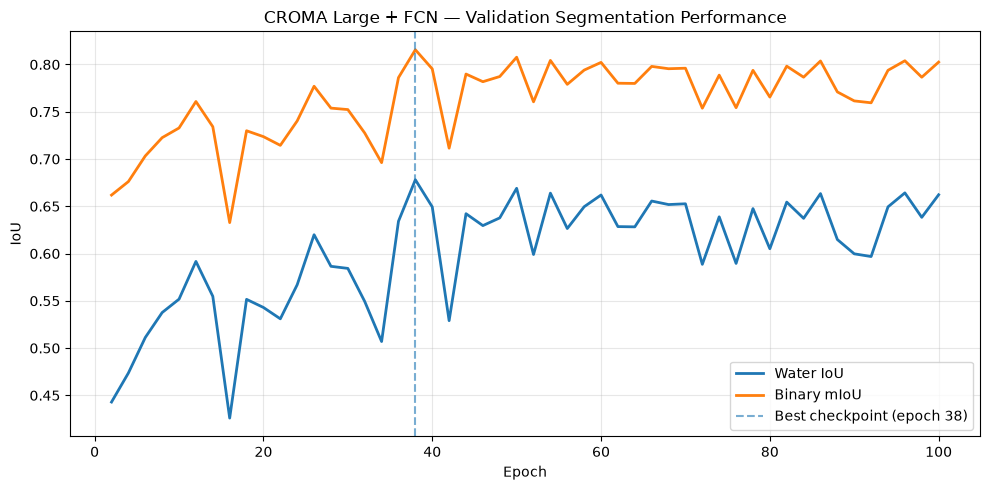

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    validation_epochs,
    [v for v in history["val_water_iou"] if v is not None],
    label="Water IoU",
    linewidth=2
)

plt.plot(
    validation_epochs,
    [v for v in history["val_miou"] if v is not None],
    label="Binary mIoU",
    linewidth=2
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best checkpoint (epoch {best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("CROMA Large + FCN — Validation Segmentation Performance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(checkpoint_dir / "validation_iou.png", dpi=150, bbox_inches="tight")
plt.show()